# 10 — A taste map: seeing Familiar / Bridge / Adventurous, not just hearing them

Notebooks 08 and 09 work entirely by *rank* in the 1280-dim EffNet embedding —
the tiers are audible but not visible. You can hear that a Bridge pick sits
somewhere between two genres, but you can't currently look at it.

This notebook flattens the full catalogue down to 2D so the tuned tier system
from notebook 09 can be looked at as well as heard. It reuses that notebook's
`explore_tiers` verbatim — same rank bands, same connecting-factor gates, same
genre cap — so what's plotted here is the actual current system, not a
simplified stand-in.

**This is a first pass**, to see what the idea looks like at all, not a
finished figure or an interface component.

In [1]:
import sys
sys.path.append("..")

import ast
from pathlib import Path
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.stats import gaussian_kde

from modeling.data import load_fma
from modeling.effnet_recommender import EffNetRecommender
from modeling.connecting_factors import ConnectingFactors

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.max_colwidth", 60)

tracks = load_fma("small")[1]
rec = EffNetRecommender.from_npz(REPO_ROOT / "data" / "effnet_embeddings_full.npz", tracks)
print(f"catalogue: {len(rec.track_ids_)} tracks")

cf = ConnectingFactors.build(tracks)

# tracks.columns is a MultiIndex; pandas won't join a MultiIndex-column frame
# against a flat one, so flatten the handful of fields the plots need once.
tracks_flat = pd.DataFrame({
    "genre": tracks[("track", "genre_top")],
    "title": tracks[("track", "title")],
    "artist": tracks[("artist", "name")],
}, index=tracks.index)

catalogue: 7994 tracks


## Flattening 1280 dimensions to 2

PCA to 50 components first (cheap, removes noise dimensions), then t-SNE with
cosine metric on top — the same metric the recommender itself uses, so
"close on the map" and "close to the model" are at least measuring the same
thing before t-SNE distorts it further for the sake of a 2D layout.

Cached to `data/taste_map_tsne_2d.npz` — this takes a couple of minutes on
the full catalogue, no reason to redo it every run.

In [2]:
CACHE_PATH = REPO_ROOT / "data" / "taste_map_tsne_2d.npz"

if CACHE_PATH.exists():
    cached = np.load(CACHE_PATH)
    ids_2d, xy = cached["ids"], cached["xy"]
    assert set(ids_2d) == set(rec.track_ids_), "cache doesn't match the current catalogue -- delete and rerun"
else:
    E = rec.embedding_.loc[rec.track_ids_].to_numpy()
    E_pca = PCA(n_components=50, random_state=0).fit_transform(E)
    xy = TSNE(n_components=2, metric="cosine", init="pca", perplexity=30, random_state=0).fit_transform(E_pca)
    ids_2d = rec.track_ids_
    np.savez(CACHE_PATH, ids=ids_2d, xy=xy)

pos = pd.DataFrame(xy, index=ids_2d, columns=["x", "y"])
print(f"projected {len(pos)} tracks")

projected 7994 tracks


## Trying a few different looks

A translucent gradient blob (the first version) was hard to read -- it's not
obvious where one genre ends and another starts. A few things fix that at
once: masking out everything below a density threshold so each genre is one
bordered region instead of a fuzzy gradient, labelling each region directly
(at its density *peak*, not its raw mean -- a stray outlier track would drag
the mean off to one side, away from where the genre actually concentrates),
and a softer colour palette with smoother edges so it reads as a map rather
than a scatterplot.

Three attempts below, same underlying density data, different styling --
pick whichever reads best and I'll carry it through the rest of the
notebook.

In [3]:
plot_df = pos.join(tracks_flat)

GENRES = sorted(tracks_flat["genre"].dropna().unique())
BW_SCALE = 2.0  # widens each genre's kernel so it reads as one cluster, not several


def rgb_tuple(rgb_str):
    return tuple(int(v) for v in rgb_str[4:-1].split(","))


pad = 0.06 * max(pos["x"].max() - pos["x"].min(), pos["y"].max() - pos["y"].min())
grid_x = np.linspace(pos["x"].min() - pad, pos["x"].max() + pad, 110)
grid_y = np.linspace(pos["y"].min() - pad, pos["y"].max() + pad, 110)
XI, YI = np.meshgrid(grid_x, grid_y)
grid_points = np.vstack([XI.ravel(), YI.ravel()])

genre_density = {}
peak_label_pos = {}
for genre in GENRES:
    sub = plot_df[plot_df["genre"] == genre]
    kde = gaussian_kde(np.vstack([sub["x"], sub["y"]]))
    kde.set_bandwidth(bw_method=kde.factor * BW_SCALE)
    zi = kde(grid_points).reshape(XI.shape)
    genre_density[genre] = zi / zi.max()
    peak_row, peak_col = np.unravel_index(np.argmax(genre_density[genre]), zi.shape)
    peak_label_pos[genre] = (grid_x[peak_col], grid_y[peak_row])

print(f"density grids ready for {len(GENRES)} genres, {len(plot_df)} tracks")

density grids ready for 8 genres, 7994 tracks


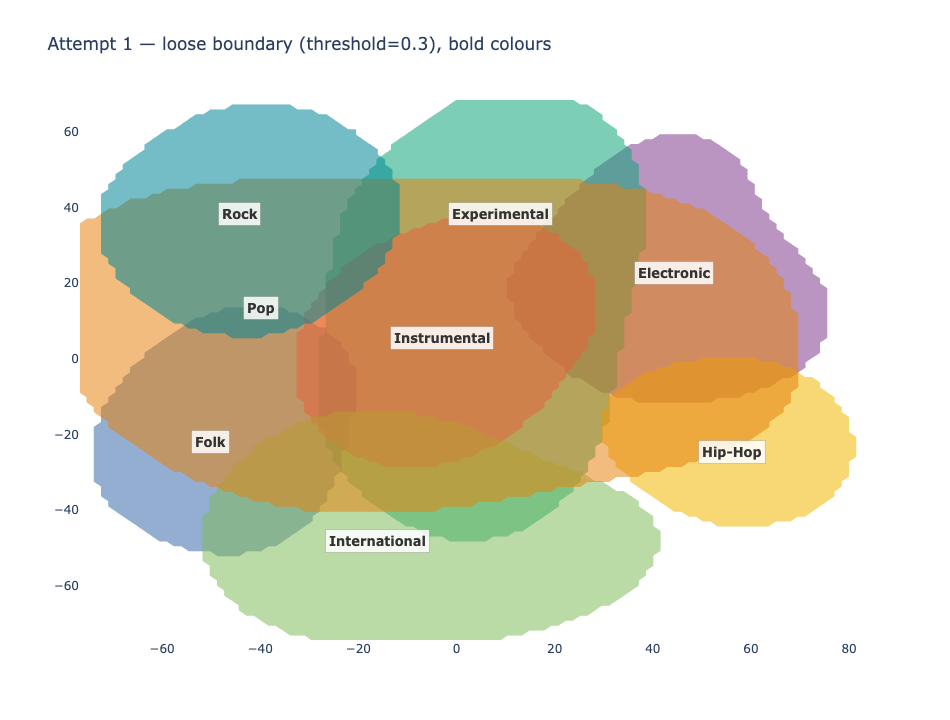

In [4]:
def cluster_figure(threshold, colors, title, alpha=0.32, line_width=2.5,
                    smoothing=1.0, show_grid=True, labels=True):
    """One bordered cluster-boundary trace per genre (everything below
    `threshold` of that genre's own peak density is masked to NaN, so Plotly
    draws nothing there rather than a fading tail), plus an on-map text label
    at each genre's density peak."""
    fig = go.Figure()
    for genre in GENRES:
        r, g, b = rgb_tuple(colors[genre])
        zi_masked = np.where(genre_density[genre] >= threshold, genre_density[genre], np.nan)
        fig.add_trace(go.Contour(
            x=grid_x, y=grid_y, z=zi_masked,
            contours=dict(start=threshold, end=1.0, size=1.0 - threshold,
                           coloring="fill", showlines=True),
            colorscale=[[0.0, f"rgba({r},{g},{b},{alpha})"], [1.0, f"rgba({r},{g},{b},{alpha})"]],
            line=dict(color=f"rgb({r},{g},{b})", width=line_width, smoothing=smoothing),
            connectgaps=False, showscale=False, hoverinfo="skip", showlegend=False,
        ))
    if labels:
        for genre in GENRES:
            cx, cy = peak_label_pos[genre]
            fig.add_annotation(x=cx, y=cy, text=f"<b>{genre}</b>", showarrow=False,
                                font=dict(size=13, color="#333"), bgcolor="rgba(255,255,255,0.85)",
                                borderpad=3, bordercolor="rgba(0,0,0,0.15)", borderwidth=1)
    fig.update_layout(
        title=title, width=950, height=720, plot_bgcolor="white", paper_bgcolor="white",
        xaxis=dict(showgrid=show_grid, zeroline=False), yaxis=dict(showgrid=show_grid, zeroline=False),
    )
    return fig


BOLD_COLORS = dict(zip(GENRES, px.colors.qualitative.Bold))
PASTEL_COLORS = dict(zip(GENRES, px.colors.qualitative.Set2))

# Static PNG, not the interactive widget -- these three are just for picking a
# style and the full interactive JSON per figure was the main thing bloating
# the notebook file and slowing VS Code down. The default carried forward
# below stays interactive (hover matters once real tracks are on the map).
cluster_figure(0.3, BOLD_COLORS, "Attempt 1 — loose boundary (threshold=0.3), bold colours").show("png")

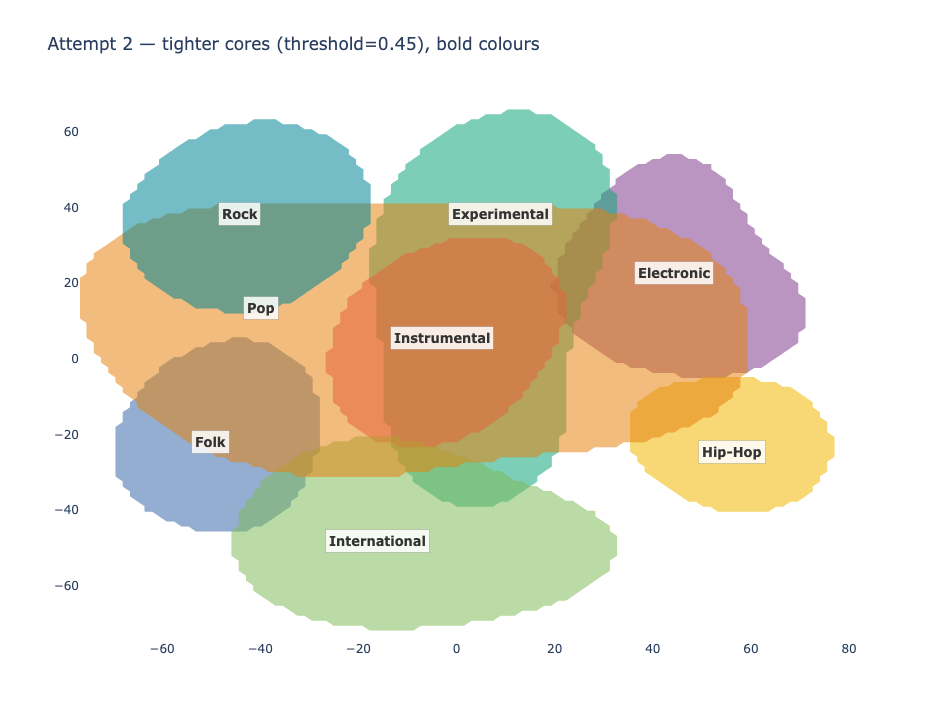

In [5]:
cluster_figure(0.45, BOLD_COLORS, "Attempt 2 — tighter cores (threshold=0.45), bold colours").show("png")

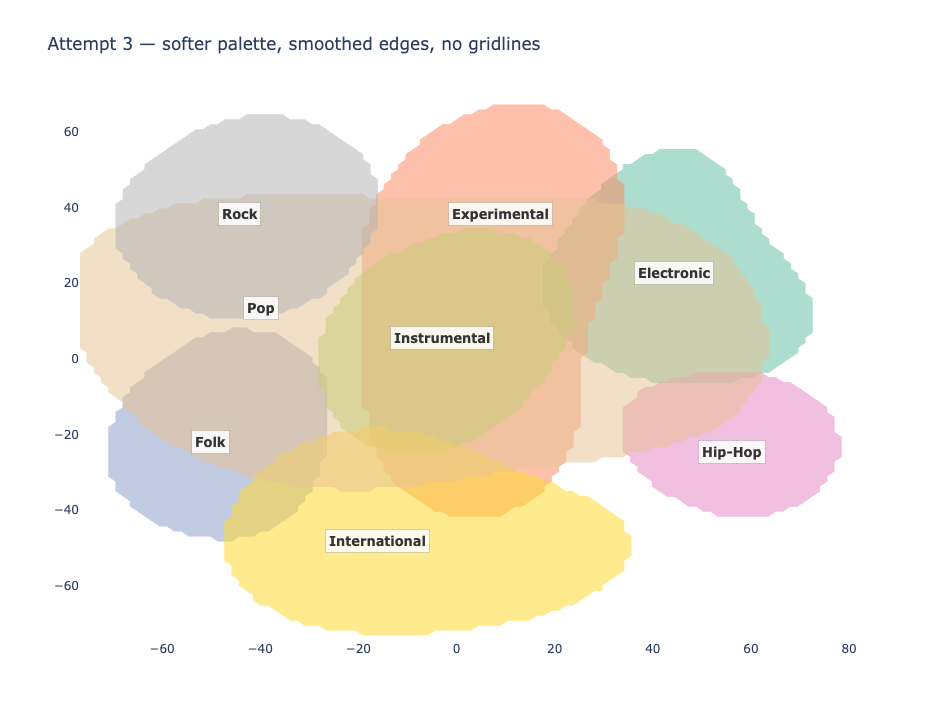

In [6]:
cluster_figure(0.4, PASTEL_COLORS, "Attempt 3 — softer palette, smoothed edges, no gridlines",
               smoothing=1.3, show_grid=False).show("png")

Defaulting to **Attempt 3** (softer palette, smoothed edges) for the rest of
this notebook — say the word if Attempt 1, 2, or something in between should
be carried forward instead.

In [7]:
GENRE_COLORS = PASTEL_COLORS
CLUSTER_THRESHOLD = 0.4
FILL_ALPHA = 0.32
LINE_SMOOTHING = 1.3


def blob_traces(density, alpha=FILL_ALPHA, legend=True):
    """One bordered cluster-boundary trace per genre, plus optional dummy
    legend markers (a Contour trace's own legend swatch isn't a clean solid
    colour, so the legend is faked with invisible Scatter points instead)."""
    traces = []
    for genre in GENRES:
        r, g, b = rgb_tuple(GENRE_COLORS[genre])
        zi_masked = np.where(density[genre] >= CLUSTER_THRESHOLD, density[genre], np.nan)
        traces.append(go.Contour(
            x=grid_x, y=grid_y, z=zi_masked,
            contours=dict(start=CLUSTER_THRESHOLD, end=1.0, size=1.0 - CLUSTER_THRESHOLD,
                           coloring="fill", showlines=True),
            colorscale=[[0.0, f"rgba({r},{g},{b},{alpha})"], [1.0, f"rgba({r},{g},{b},{alpha})"]],
            line=dict(color=f"rgb({r},{g},{b})", width=2, smoothing=LINE_SMOOTHING),
            connectgaps=False, showscale=False, hoverinfo="skip", showlegend=False,
        ))
    if legend:
        for genre in GENRES:
            traces.append(go.Scatter(
                x=[None], y=[None], mode="markers",
                marker=dict(size=10, color=GENRE_COLORS[genre]),
                name=genre, hoverinfo="skip",
            ))
    return traces

## Putting a seed and its tiers on the map

`explore_tiers`, `_cap_same_genre` and the tuned round-2 parameters below are
copied verbatim from notebook 09 — same rank bands, same `gate_factors`
(Bridge requires a shared `era`, Adventurous requires nothing), same 25%
same-genre cap with widening. Nothing about the tier logic is re-tuned here.

In [8]:
ALL_FACTORS = ("genre", "genre_lineage", "era", "geography")


def _genre_top(track_id):
    return tracks.loc[track_id, ("track", "genre_top")]


def _cap_same_genre(pool_idx, candidate_ids, seed_id, seed_genre, n, max_share,
                     allowed_set, rng, widen_to=None):
    pool_idx = list(pool_idx)
    if seed_genre is None or not pool_idx:
        return list(rng.choice(pool_idx, size=min(n, len(pool_idx)), replace=False)) if pool_idx else []

    same = [i for i in pool_idx if _genre_top(candidate_ids[i]) == seed_genre]
    diff = [i for i in pool_idx if _genre_top(candidate_ids[i]) != seed_genre]
    max_same = int(np.floor(n * max_share))
    n_same = min(max_same, len(same))
    needed_diff = n - n_same

    if len(diff) < needed_diff and widen_to is not None and pool_idx and widen_to > pool_idx[-1]:
        for j in range(pool_idx[-1] + 1, widen_to):
            if len(diff) >= needed_diff:
                break
            if _genre_top(candidate_ids[j]) == seed_genre:
                continue
            if allowed_set is not None and seed_id is not None:
                if not (set(cf.factors_between(seed_id, candidate_ids[j])) & allowed_set):
                    continue
            diff.append(j)

    n_diff = min(needed_diff, len(diff))
    if n_same + n_diff < n:
        n_same = min(len(same), n - n_diff)

    chosen = list(rng.choice(same, size=n_same, replace=False)) if n_same else []
    chosen += diff[:n_diff]
    return chosen if chosen else pool_idx[: min(n, len(pool_idx))]


def explore_tiers(seed_id=None, seed_vec=None, seed_artist=None,
                   familiar=(0, 15), bridge=(30, 150), adventurous=(500, 2000), n=5,
                   gate_factors=None, max_same_genre_share=None, widen_to=None, seed=0):
    gate_factors = gate_factors or {"Bridge": ("era",), "Adventurous": None}
    max_same_genre_share = {"Bridge": 0.25} if max_same_genre_share is None else max_same_genre_share
    widen_to = {"Bridge": adventurous[0]} if widen_to is None else widen_to

    if seed_vec is None:
        row = rec._position(seed_id)
        seed_vec = rec.embedding_.iloc[[row]]
    widen_values = [v for v in widen_to.values() if v is not None]
    search_n = max(adventurous[1] + 1, (max(widen_values) + 1) if widen_values else 0, 50)
    distances, idx = rec.index_.kneighbors(seed_vec, n_neighbors=search_n)
    distances, idx = distances[0], idx[0]
    if seed_id is not None:
        distances, idx = distances[1:], idx[1:]
    candidate_ids = rec.track_ids_[idx]

    if seed_artist is not None:
        artists = tracks.loc[candidate_ids, ("artist", "name")].to_numpy()
        keep = artists != seed_artist
        candidate_ids, distances = candidate_ids[keep], distances[keep]

    seed_genre = _genre_top(seed_id) if seed_id is not None else None

    rng = np.random.default_rng(seed)
    out = {}
    for label, (lo, hi) in [("Familiar", familiar), ("Bridge", bridge), ("Adventurous", adventurous)]:
        hi = min(hi, len(candidate_ids))
        pool_idx = np.arange(lo, hi)

        allowed = gate_factors.get(label) if label in gate_factors else "skip"
        allowed_set = set(allowed or ALL_FACTORS) if allowed != "skip" else None
        if allowed_set is not None and seed_id is not None and len(pool_idx):
            connected = [i for i in pool_idx if set(cf.factors_between(seed_id, candidate_ids[i])) & allowed_set]
            pool_for_pick = connected if len(connected) >= n else list(pool_idx)
        else:
            pool_for_pick = list(pool_idx)

        share = max_same_genre_share.get(label) if label in max_same_genre_share else None
        if share is not None:
            pick = _cap_same_genre(pool_for_pick, candidate_ids, seed_id, seed_genre, n, share,
                                    allowed_set, rng, widen_to=widen_to.get(label))
        else:
            pick = list(rng.choice(pool_for_pick, size=min(n, len(pool_for_pick)), replace=False)) if pool_for_pick else []
        pick = sorted(pick)
        factors = [cf.factors_between(seed_id, candidate_ids[i]) if seed_id is not None else [] for i in pick]
        out[label] = [(candidate_ids[i], distances[i], i + 1, f) for i, f in zip(pick, factors)]
    return out


familiar = (0, 15)
bridge = (30, 150)
adventurous = (500, 2000)
gate_factors = {"Bridge": ("era",), "Adventurous": None}
max_same_genre_share = {"Bridge": 0.25}
widen_to = {"Bridge": adventurous[0]}

In [9]:
def tiers_to_frame(seed_id, tiers):
    rows = []
    for label, items in tiers.items():
        for tid, dist, rank, factors in items:
            rows.append({"track_id": tid, "tier": label, "distance": dist, "rank": rank,
                         "factors": ", ".join(factors) if factors else "—"})
    df = pd.DataFrame(rows).set_index("track_id").join(pos).join(tracks_flat)
    return df


TIER_COLORS = {"Familiar": "#3B82F6", "Bridge": "#F59E0B", "Adventurous": "#EF4444"}


def tier_figure(seed_id, tier_df, title):
    fig = go.Figure(data=blob_traces(genre_density, alpha=0.35, legend=False))
    for label, color in TIER_COLORS.items():
        sub = tier_df[tier_df["tier"] == label]
        fig.add_trace(go.Scattergl(
            x=sub["x"], y=sub["y"], mode="markers", name=label,
            marker=dict(size=11, color=color, line=dict(width=1, color="white")),
            text=[f"{r.title} — {r.artist}<br>{r.genre} · rank {r['rank']} · dist {r.distance:.3f}<br>via {r.factors}"
                  for _, r in sub.iterrows()],
            hoverinfo="text",
        ))
    seed_xy = pos.loc[seed_id]
    seed_meta = tracks.loc[seed_id]
    fig.add_trace(go.Scattergl(
        x=[seed_xy.x], y=[seed_xy.y], mode="markers+text", name="Seed",
        marker=dict(size=18, color="black", symbol="star", line=dict(width=1, color="white")),
        text=["SEED"], textposition="top center",
        hovertext=[f"{seed_meta[('artist','name')]} — {seed_meta[('track','title')]}"],
        hoverinfo="text",
    ))
    fig.update_layout(title=title, width=1000, height=750, legend_title_text="Tier")
    return fig


SEED_ID = 2  # AWOL - Food, Hip-Hop -- same seed used throughout notebooks 07-09
seed_meta = tracks.loc[SEED_ID]
tiers = explore_tiers(seed_id=SEED_ID, seed_artist=seed_meta[("artist", "name")],
                       familiar=familiar, bridge=bridge, adventurous=adventurous, n=15,
                       gate_factors=gate_factors, max_same_genre_share=max_same_genre_share, widen_to=widen_to)
tier_df = tiers_to_frame(SEED_ID, tiers)

fig = tier_figure(SEED_ID, tier_df,
                   f"Familiar / Bridge / Adventurous around {seed_meta[('artist','name')]} — {seed_meta[('track','title')]}")
fig.show()
tier_df.sort_values(["tier", "rank"])

,tier,distance,rank,factors,x,y,genre,title,artist
track_id,,,,,,,,,
10693,Adventurous,0.388273,507,"genre, geography",43.988136,-7.568127,Hip-Hop,6.6.05,BOPD
135336,Adventurous,0.389424,510,geography,66.584366,-22.451664,Pop,Slow and Steady,Caleb Lemond
22295,Adventurous,0.393410,525,genre,49.109783,-17.538837,Hip-Hop,Sorry,Comfort Fit
142093,Adventurous,0.394938,532,"genre, geography",66.494194,-19.407915,Hip-Hop,"Lights, it was you and I",SK
108774,Adventurous,0.411038,588,genre,45.679035,-27.385155,Hip-Hop,Bloc Party (Instrumental),Cheese N Pot-C
64631,Adventurous,0.425565,640,genre,52.634007,-7.462239,Hip-Hop,Flava,Blank & Kytt
97989,Adventurous,0.476096,833,"genre, geography",9.036444,-39.037102,Hip-Hop,Think Logical (Featuring E FeungShui) (Accapella),Deadly Combo
40842,Adventurous,0.504591,969,"era, geography",56.394779,1.980851,Electronic,Death Proof,Fancy Mike
86416,Adventurous,0.508953,997,genre,38.814014,-10.520666,Hip-Hop,One Hundred 10 (BPM) (Instrumental),The Impossebulls


## The same three tiers, on the three seeds used throughout 07-09

Hip-Hop (coherent), Instrumental (best genre-agreement), Pop (the
acoustically incoherent one) — the same three catalogue seeds used to tune
`explore_tiers` in notebook 09. If Pop's Bridge/Adventurous points look more
scattered than Hip-Hop's, that's the same "Pop has no consistent acoustic
identity" finding from notebooks 06 and 08, now visible rather than only
measured.

In [10]:
ROUND_SEEDS = [2, 40659, 3538]  # AWOL - Food; Albert Glasser - The Auction 2; Cryptacize - Say You Will

sub_titles = []
seed_tier_dfs = {}
for seed_id in ROUND_SEEDS:
    m = tracks.loc[seed_id]
    t = explore_tiers(seed_id=seed_id, seed_artist=m[("artist", "name")],
                       familiar=familiar, bridge=bridge, adventurous=adventurous, n=15,
                       gate_factors=gate_factors, max_same_genre_share=max_same_genre_share, widen_to=widen_to)
    seed_tier_dfs[seed_id] = tiers_to_frame(seed_id, t)
    sub_titles.append(f"{m[('track','genre_top')]}: {m[('artist','name')]} — {m[('track','title')]}")

fig = make_subplots(rows=1, cols=3, subplot_titles=sub_titles, horizontal_spacing=0.04)

for col, seed_id in enumerate(ROUND_SEEDS, start=1):
    tdf = seed_tier_dfs[seed_id]
    for t in blob_traces(genre_density, alpha=0.3, legend=False):
        fig.add_trace(t, row=1, col=col)
    for label, color in TIER_COLORS.items():
        sub = tdf[tdf["tier"] == label]
        fig.add_trace(go.Scattergl(
            x=sub["x"], y=sub["y"], mode="markers", name=label,
            marker=dict(size=8, color=color, line=dict(width=0.5, color="white")),
            legendgroup=label, showlegend=(col == 1),
            text=[f"{r.title} — {r.artist} · rank {r['rank']}" for _, r in sub.iterrows()],
            hoverinfo="text",
        ), row=1, col=col)
    seed_xy = pos.loc[seed_id]
    fig.add_trace(go.Scattergl(
        x=[seed_xy.x], y=[seed_xy.y], mode="markers", name="Seed",
        marker=dict(size=13, color="black", symbol="star", line=dict(width=1, color="white")),
        legendgroup="Seed", showlegend=(col == 1),
    ), row=1, col=col)

fig.update_layout(width=1500, height=560, title="Tier spread across three genres of differing acoustic coherence")
fig.show()

## Caveats before reading too much into this

- **t-SNE distances are not the model's distances.** The recommender ranks
  neighbours in the real 1280-dim cosine space; t-SNE distorts that into 2D
  for the sake of a picture. Two points drawn close together are not
  guaranteed close in the space that actually drives recommendations, and
  vice versa — treat this as an illustration of structure, not a source of
  truth.
- **Each genre's cluster boundary is relative to its own peak density**, not
  to track count. A genre with fewer tracks can still draw a full-sized
  cluster wherever its tracks happen to concentrate — the boundary shows
  "where this genre is concentrated", not "how much of the catalogue is this
  genre".
- **This is one seed's neighbourhood at a time**, drawn on a fixed background
  computed once for the whole catalogue. Re-running `explore_tiers` for a
  different seed re-uses the same map, which is what makes the three-genre
  comparison above meaningful.
- **Next steps, if this is worth taking further:** turn the seed into a
  dropdown/search box (ties into the frontend's `GET /tracks?query=` search),
  and swap the static PNG-like scatter for something that updates live as the
  adventure dial moves, rather than three fixed rank bands.